In [1]:
import os, sys
# work from the project folder so we can import from src/
os.chdir("/workspaces/nyc-ems-demand-pipeline")   
sys.path.insert(0, os.getcwd())                     

import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_config, load_hourly

config = load_config()
df = load_hourly(config["data"]["history_start"], config["data"]["replay_end"], config)
df["hour"] = df["timestamp"].dt.hour
df["day_name"] = df["timestamp"].dt.day_name()
df["date"] = df["timestamp"].dt.date
print(df.shape)
df.head()


(164280, 6)


,timestamp,borough,calls,hour,day_name,date
0,2023-01-01 00:00:00,BRONX,52,0,Sunday,2023-01-01
1,2023-01-01 01:00:00,BRONX,39,1,Sunday,2023-01-01
2,2023-01-01 02:00:00,BRONX,43,2,Sunday,2023-01-01
3,2023-01-01 03:00:00,BRONX,37,3,Sunday,2023-01-01
4,2023-01-01 04:00:00,BRONX,37,4,Sunday,2023-01-01


### Chart 1: How calls changes across the day?
The question: when during the day do calls peak and dip? 
This tells us whether the 8-hour shifts (12am–8am, 8am–4pm, 4pm–12am) are good splits.

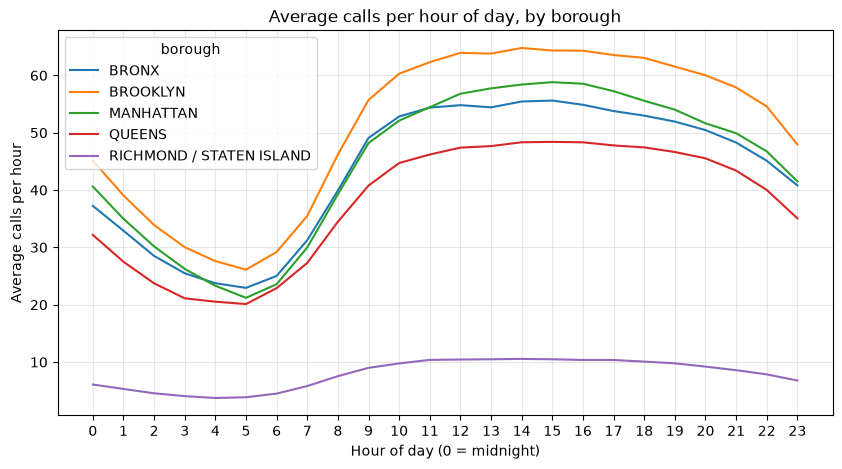

In [2]:
# Chart 1: How calls change across the day?
hourly = df.groupby(["hour", "borough"])["calls"].mean().unstack()
hourly.plot(figsize=(10, 5), title="Average calls per hour of day, by borough")
plt.xlabel("Hour of day (0 = midnight)")
plt.ylabel("Average calls per hour")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.show()

Calls bottom out around 4–5am, rise sharply until about 10am, plateau until about 6pm, then decline. All boroughs share this shape at different levels, which supports one combined model with borough as a feature. Manhattan passes the Bronx during the day, likely reflecting its daytime population. Staten Island is about 6× lower and flatter.

### Chart 2: Day of the week

The question: are weekends different from weekdays, and do we need day-of-week and weekend features?

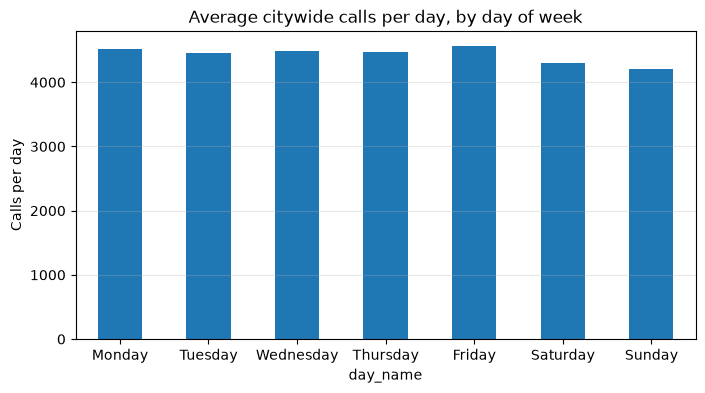

In [3]:
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
daily = df.groupby(["date", "day_name"])["calls"].sum().reset_index()
daily.groupby("day_name")["calls"].mean().reindex(order).plot(
    kind="bar", figsize=(8, 4), title="Average citywide calls per day, by day of week")
plt.ylabel("Calls per day")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [4]:
print(daily.groupby("day_name")["calls"].mean().reindex(order).round(0))

day_name
Monday       4516.0
Tuesday      4459.0
Wednesday    4483.0
Thursday     4474.0
Friday       4569.0
Saturday     4307.0
Sunday       4204.0
Name: calls, dtype: float64


Weekdays average about 4,500 calls a day, with Friday highest (4,569). Saturday is about 4% lower and Sunday about 7% lower (4,204). Day of week and a weekend flag stay as features.

### Chart 3: Calls over time (2023–2026). 

The question: are there seasonal patterns, long-term trends, or sudden jumps? This matters for drift monitoring in the replay.

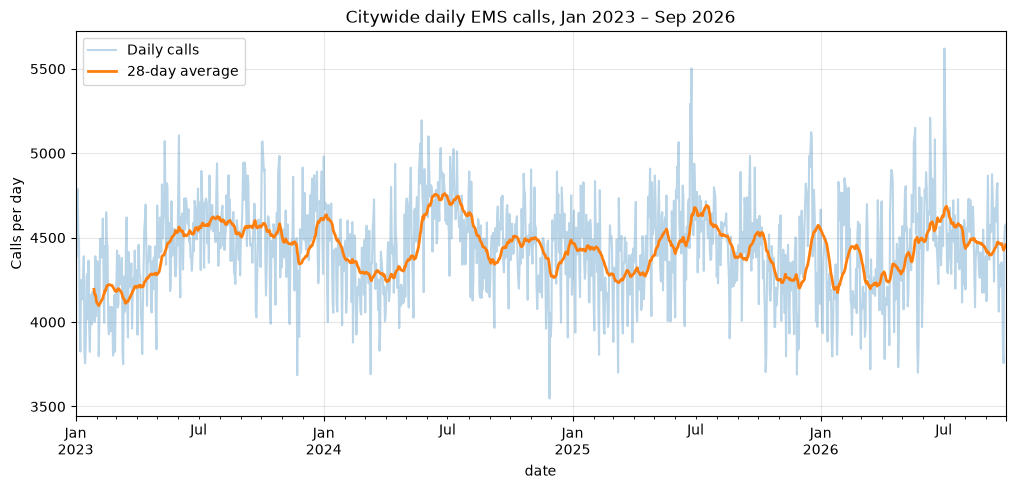

In [5]:
city = df.groupby("date")["calls"].sum()
city.index = pd.to_datetime(city.index)
ax = city.plot(figsize=(12, 5), alpha=0.3, label="Daily calls")
city.rolling(28).mean().plot(ax=ax, label="28-day average", linewidth=2)
plt.title("Citywide daily EMS calls, Jan 2023 – Sep 2026")
plt.ylabel("Calls per day")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Citywide calls range from about 4,200 to 4,750 a day, with no strong long-term trend. There’s a clear summer peak (June–July) and a smaller December–January bump, likely flu season and the holidays. Sharp single-day spikes in early summer (about 5,500–5,600) are likely heat waves or July 4th, and will be the hardest days to predict without weather data. With 2 years of history, Prophet can use yearly seasonality.

### Chart 4: Monthly calls by borough

The question: do all boroughs rise and fall together across the year? If they do, one combined model is the right choice.

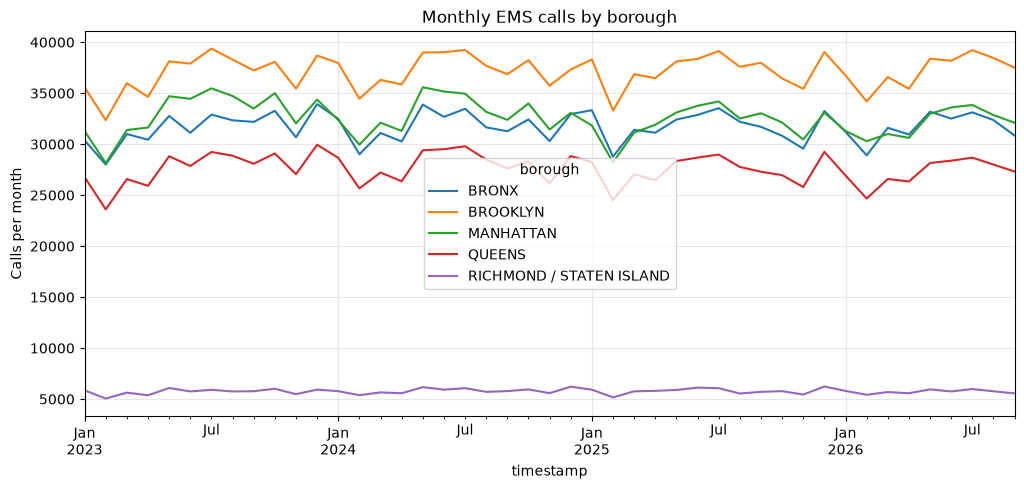

In [6]:
monthly = df.set_index("timestamp").groupby("borough")["calls"].resample("MS").sum().unstack(0)
monthly.plot(figsize=(12, 5), title="Monthly EMS calls by borough")
plt.ylabel("Calls per month")
plt.grid(alpha=0.3)
plt.show()

The boroughs move together. They rise and fall in the same months, and their order stays mostly stable.The February dip every year is partly an illusion. February has only 28 days, so a monthly total is lower just because the month is shorter. The same goes for 30-day versus 31-day months. To compare months fairly,we use the average calls per day instead of the monthly total.

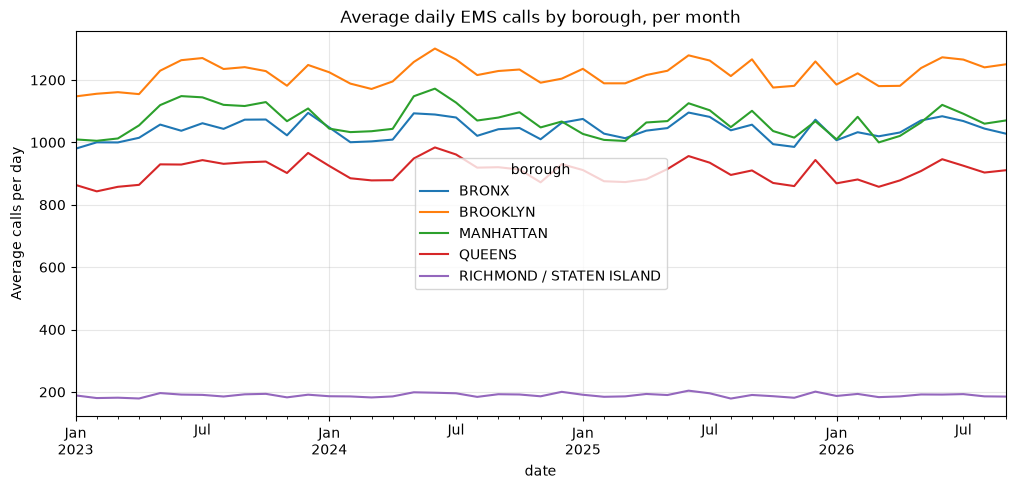

In [7]:
daily_b = df.groupby(["date", "borough"])["calls"].sum().reset_index()
daily_b["date"] = pd.to_datetime(daily_b["date"])
monthly_avg = daily_b.set_index("date").groupby("borough")["calls"].resample("MS").mean().unstack(0)
monthly_avg.plot(figsize=(12, 5), title="Average daily EMS calls by borough, per month")
plt.ylabel("Average calls per day")
plt.grid(alpha=0.3)
plt.show()

Using average calls per day removes the false February dip. The real pattern is a summer peak (strongest in June 2024), a smaller December bump, and lower months in late winter and spring. All boroughs move together, and the Bronx has matched Manhattan since late 2024.

### Chart 5 (last cell): The busiest and quietest days

The question: which specific days are unusual, and why? These are where the model will struggle most.

In [8]:
print("Busiest days:")
print(city.sort_values(ascending=False).head(10))
print("\nQuietest days:")
print(city.sort_values().head(10))

Busiest days:
date
2026-07-02    5620
2025-06-25    5502
2025-06-23    5293
2026-07-03    5225
2026-06-11    5210
2025-06-24    5207
2024-05-24    5195
2026-05-20    5151
2025-12-18    5125
2023-06-02    5106
Name: calls, dtype: int64

Quietest days:
date
2024-11-28    3547
2023-11-23    3685
2025-11-27    3689
2024-03-10    3691
2025-03-09    3700
2026-05-24    3700
2025-10-12    3704
2026-03-15    3720
2026-04-25    3733
2023-03-12    3751
Name: calls, dtype: int64


The two biggest spikes match NYC heat waves: June 23–25, 2025 and July 2–3, 2026. July 2, 2026 was the busiest day in the data (5,620 calls), when Central Park hit a record-tying 100°F. Weather has little effect on average days but drives the most extreme ones, so heat waves will be the model’s largest errors. A forecast-based heat warning flag is a natural future improvement.